In [6]:
import os
import matplotlib.pyplot as plt

In [7]:
data_folder = "../data/20250630"

file_paths =[
    "20250630_213940_data.txt",
    "20250630_214428_data.txt",
    "20250630_214843_data.txt",
    "20250630_215347_data.txt",
    "20250630_220021_data.txt",
    "20250630_220508_data.txt",
    "20250630_220953_data.txt",
    "20250630_221442_data.txt",
    "20250630_222042_data.txt",
    "20250630_222537_data.txt"
]

row_data = []
row_csi = []

row_amp = []    # 振幅
row_phase = []  # 位相

# 前処理
buttter_filtered__csi = []
median_filtered_csi = []

# 分割
split_data = []
split_csi = []
merged_split_data = []  # [ラベル][分割後データ数][データ]
merged_split_csi = []   # [ラベル][分割後データ数][CSI]

In [8]:
# row_dataリストにデータを格納する
# row_data[ラベル番号][ファイル番号][各行のCSIデータ]
# 各行のデータ：{'no': 行番号, 'ms': ミリ秒, 'csi': CSIデータ(10進数)}

def parse_csi_line(line):
    parts = line.strip().split(',')
    no = int(parts[0])
    ms = int(parts[1])
    csi_hex = parts[2]
    # 2桁ずつ符号付き整数（-128～127）に変換
    def hex_to_signed_int(h):
        val = int(h, 16)
        if val >= 128:
            val -= 256
        return val
    csi = [hex_to_signed_int(csi_hex[i:i+2]) for i in range(0, len(csi_hex), 2)]
    return {'no': no, 'ms': ms, 'csi': csi}


row_data = []
row_csi = []

for i in range(1, 43):  # 1~42
    folder_data = []
    folder_csi = []
    folder = data_folder + '/' + str(i)
    for fname in file_paths:
        file_data = []
        fpath = folder + '/' + fname
        with open(fpath) as f:
            for line in f:
                file_data.append(parse_csi_line(line))
        folder_data.append([[row['no'], row['ms']] for row in file_data])
        folder_csi.append([row['csi'] for row in file_data])
    row_data.append(folder_data)
    row_csi.append(folder_csi)

In [9]:
# 振幅と位相を分割

row_amp = []
row_phase = []

for label in row_csi:
    label_amp = []
    label_phase = []
    for file in label:
        file_amp = []
        file_phase = []
        for row in file:
            amp = row[::2]    # 偶数インデックスが振幅
            phase = row[1::2] # 奇数インデックスが位相
            file_amp.append(amp)
            file_phase.append(phase)
        label_amp.append(file_amp)
        label_phase.append(file_phase)
    row_amp.append(label_amp)
    row_phase.append(label_phase)

In [10]:
# 前処理：バターワースフィルタ

from scipy.signal import butter, filtfilt

def butter_lowpass_filter(data, cutoff, fs, order=4):
    nyq = 0.5 * fs  # ナイキスト周波数
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    y = filtfilt(b, a, data)
    return y


# row_csi[ラベル][ファイル][行][CSI]
buttter_filtered__csi = []
cutoff = 10
fs = 79
order = 4

for label in row_phase:
    filtered_label = []
    for file in label:
        # 各行のCSI（リスト）を転置してアンテナごとにフィルタをかける
        if len(file) == 0:
            filtered_file = []
        else:
            # CSIデータを転置（[行][サブキャリア]→[サブキャリア][行]）
            csi_array = list(zip(*file))
            # 各サブキャリアごとにフィルタ
            filtered_csi_array = [butter_lowpass_filter(list(subc), cutoff, fs, order) for subc in csi_array]
            # 元の形に戻す（[サブキャリア][行]→[行][サブキャリア]）
            filtered_file = [list(x) for x in zip(*filtered_csi_array)]
        filtered_label.append(filtered_file)
    buttter_filtered__csi.append(filtered_label)

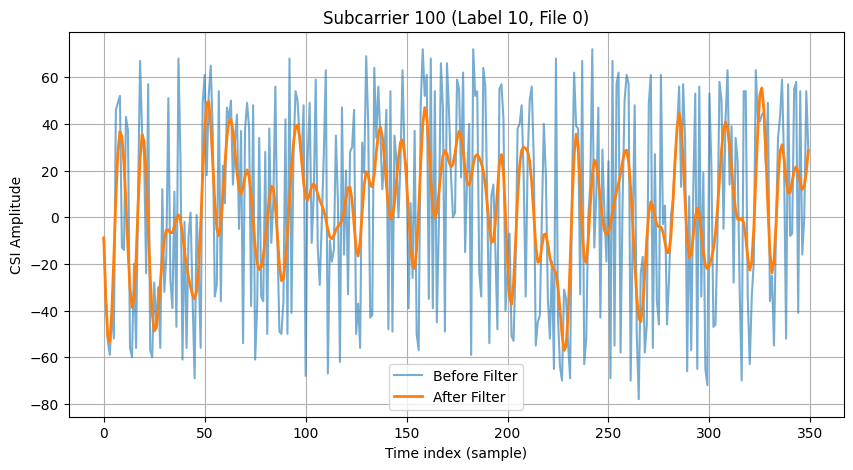

In [11]:
# フィルタの動作確認

# 対象インデックス（例：ラベル0・ファイル0・サブキャリア10）
label_idx = 10
file_idx = 0
subc_idx = 100  # 任意のサブキャリア番号

# フィルタ前のCSI（時系列）
original_csi = [row[subc_idx] for row in row_phase[label_idx][file_idx]]

# フィルタ後のCSI（時系列）
filtered_csi = [row[subc_idx] for row in buttter_filtered__csi[label_idx][file_idx]]

# プロット
plt.figure(figsize=(10, 5))
plt.plot(original_csi, label="Before Filter", alpha=0.6)
plt.plot(filtered_csi, label="After Filter", linewidth=2)
plt.title(f"Subcarrier {subc_idx} (Label {label_idx}, File {file_idx})")
plt.xlabel("Time index (sample)")
plt.ylabel("CSI Amplitude")
plt.legend()
plt.grid(True)
plt.show()


In [12]:
# 前処理：メディアンフィルタ
from scipy.signal import medfilt

def median_filter(data, kernel_size=3):
    # data: 1次元リスト
    return medfilt(data, kernel_size=kernel_size)

# row_csi[ラベル][ファイル][行][CSI]
median_filtered_csi = []
kernel_size = 3 # メディアンフィルタの窓幅

for label in buttter_filtered__csi:
    median_label = []
    for file in label:
        if len(file) == 0:
            median_file = []
        else:
            # CSIデータを転置（[行][サブキャリア]→[サブキャリア][行]）
            csi_array = list(zip(*file))
            # 各サブキャリアごとにメディアンフィルタ
            median_csi_array = [median_filter(list(subc), kernel_size) for subc in csi_array]
            # 元の形に戻す（[サブキャリア][行]→[行][サブキャリア]）
            median_file = [list(x) for x in zip(*median_csi_array)]
        median_label.append(median_file)
    median_filtered_csi.append(median_label)

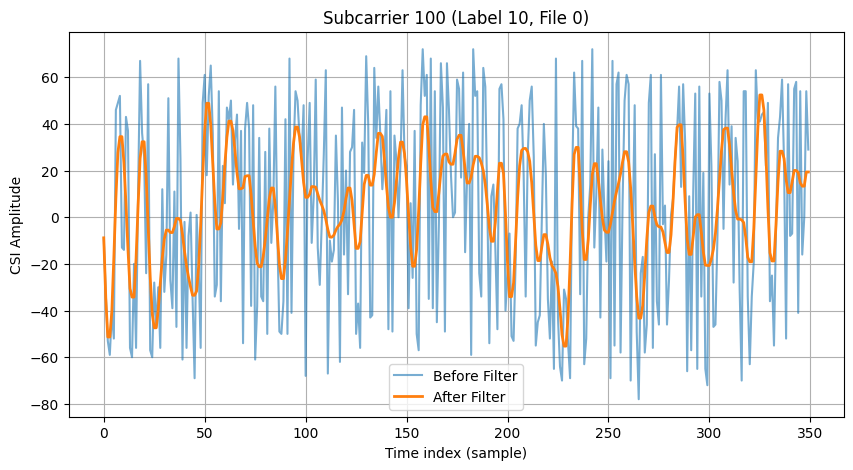

In [13]:
# フィルタの動作確認

# 対象インデックス（例：ラベル0・ファイル0・サブキャリア10）
label_idx = 10
file_idx = 0
subc_idx = 100  # 任意のサブキャリア番号

# フィルタ前のCSI（時系列）
original_csi = [row[subc_idx] for row in row_phase[label_idx][file_idx]]

# フィルタ後のCSI（時系列）
filtered_csi = [row[subc_idx] for row in median_filtered_csi[label_idx][file_idx]]

# プロット
plt.figure(figsize=(10, 5))
plt.plot(original_csi, label="Before Filter", alpha=0.6)
plt.plot(filtered_csi, label="After Filter", linewidth=2)
plt.title(f"Subcarrier {subc_idx} (Label {label_idx}, File {file_idx})")
plt.xlabel("Time index (sample)")
plt.ylabel("CSI Amplitude")
plt.legend()
plt.grid(True)
plt.show()


In [15]:
# row_data: [ラベル][ファイル][[no, ms], ...]
# row_csi:  [ラベル][ファイル][CSI, ...]
# 500msごとに分割（各ファイルの先頭msを基準に相対時間で分割）

split_data = []
split_csi = []
interval_ms = 500

for label_idx, label in enumerate(row_data):
    label_split_data = []
    label_split_csi = []
    for file_idx, file in enumerate(label):
        if not file:
            label_split_data.append([])
            label_split_csi.append([])
            continue
        base_ms = file[0][1]  # 各ファイルの先頭msを基準
        seg_data = []
        seg_csi = []
        segments_data = []
        segments_csi = []
        for idx, (no, ms) in enumerate(file):
            rel_ms = ms - base_ms
            if rel_ms // interval_ms == len(segments_data):
                seg_data.append([no, ms])
                seg_csi.append(median_filtered_csi[label_idx][file_idx][idx])
            else:
                if len(seg_data) > 0:
                    segments_data.append(seg_data)
                    segments_csi.append(seg_csi)
                seg_data = [[no, ms]]
                seg_csi = [median_filtered_csi[label_idx][file_idx][idx]]
        # 最後の端数は追加しない（端数削除）
        label_split_data.append(segments_data)
        label_split_csi.append(segments_csi)
    split_data.append(label_split_data)
    split_csi.append(label_split_csi)

In [16]:
# split_data: [ラベル][ファイル][分割後データ数][データ]
# split_csi:  [ラベル][ファイル][分割後データ数][CSI]

merged_split_data = []
merged_split_csi = []

for label_data, label_csi in zip(split_data, split_csi):
    merged_data = []
    merged_csi = []
    for file_data, file_csi in zip(label_data, label_csi):
        merged_data.extend(file_data)
        merged_csi.extend(file_csi)
    merged_split_data.append(merged_data)
    merged_split_csi.append(merged_csi)

# merged_split_data: [ラベル][分割後データ数][データ]
# merged_split_csi:  [ラベル][分割後データ数][CSI]

In [17]:
# 特徴量抽出関数
import numpy as np
from scipy.stats import kurtosis, skew

def extract_features_per_subcarrier(segment_csi):
    # segment_csi: [サンプル][サブキャリア]
    segment_csi = np.array(segment_csi)
    features_per_subc = []
    for subc in segment_csi.T:
        features = {
            "平均": float(np.mean(subc)),
            "中央値": float(np.median(subc)),
            "標準偏差": float(np.std(subc)),
            "最大値": float(np.max(subc)),
            "最小値": float(np.min(subc)),
            "上四分位値": float(np.percentile(subc, 75)),
            "下四分位値": float(np.percentile(subc, 25)),
            "四分位範囲": float(np.percentile(subc, 75) - np.percentile(subc, 25)),
            "平均絶対偏差": float(np.mean(np.abs(subc - np.mean(subc)))),
            "尖度": float(kurtosis(subc)) if len(subc) > 3 else None,
            "歪度": float(skew(subc)) if len(subc) > 2 else None,
            "自己相関": float(np.corrcoef(subc[:-1], subc[1:])[0, 1]) if len(subc) > 1 else None,
            "二乗平均平方根": float(np.sqrt(np.mean(subc ** 2)))
        }
        features_per_subc.append(features)
    return features_per_subc

# 例: ラベル0の1つ目の分割データに対して
features = extract_features_per_subcarrier(merged_split_csi[0][0])
print(features[50])

{'平均': -0.02618275009874792, '中央値': -0.7290608621350438, '標準偏差': 2.309076794299922, '最大値': 3.976808337866095, '最小値': -3.745668157594699, '上四分位値': 2.210713663750554, '下四分位値': -1.880466826982489, '四分位範囲': 4.091180490733043, '平均絶対偏差': 2.0054628322953536, '尖度': -1.173076649603652, '歪度': 0.25420015635491816, '自己相関': 0.8819096904169895, '二乗平均平方根': 2.3092252333579624}


/Users/tanakakeiji/研究コード/reserch-analysis/venv/lib/python3.9/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# 特徴量抽出
X = []
y = []
for label_idx, label_csi in enumerate(merged_split_csi):
    for segment in label_csi:
        # 各サブキャリアごとの特徴量を1つのベクトルにまとめる
        features = []
        for subc_features in extract_features_per_subcarrier(segment):
            features.extend(subc_features.values())
        X.append(features)
        y.append(label_idx)

# データ分割
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# ランダムフォレストで学習・予測
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# 結果表示
print(classification_report(y_test, y_pred, digits=3))

/Users/tanakakeiji/研究コード/reserch-analysis/venv/lib/python3.9/site-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


              precision    recall  f1-score   support

           0      0.053     0.048     0.050        21
           1      0.077     0.048     0.059        21
           2      0.000     0.000     0.000        20
           3      0.000     0.000     0.000        19
           4      0.000     0.000     0.000        20
           5      0.000     0.000     0.000        20
           6      0.037     0.048     0.042        21
           7      0.000     0.000     0.000        21
           8      0.062     0.048     0.054        21
           9      0.059     0.045     0.051        22
          10      0.000     0.000     0.000        21
          11      0.000     0.000     0.000        22
          12      0.040     0.045     0.043        22
          13      0.067     0.045     0.054        22
          14      0.114     0.148     0.129        27
          15      0.000     0.000     0.000        24
          16      0.000     0.000     0.000        23
          17      0.067    